In [31]:
pip install -U matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached matplotlib-3.3.4-cp36-cp36m-manylinux1_x86_64.whl (11.5 MB)
     |████████████████████████████████| 3.1 MB 5.0 MB/s            
  Using cached kiwisolver-1.3.1-cp36-cp36m-manylinux1_x86_64.whl (1.1 MB)
  Using cached cycler-0.11.0-py3-none-any.whl (6.4 kB)
  Attempting uninstall: pillow
    Found existing installation: Pillow 6.0.0
    Uninstalling Pillow-6.0.0:
      Successfully uninstalled Pillow-6.0.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import random
import pandas as pd
from datasets import Dataset, Features, Value, ClassLabel
import collections
from collections import Counter
import matplotlib.pyplot as plt
from pathlib import Path
from datasets import DatasetDict

import torch
from transformers import AdamW, AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding


In [2]:
#training set
training_set = [os.path.join("classifier-dataset/dataset/trainning_set", f) for f in os.listdir("classifier-dataset/dataset/trainning_set")]

#test_set 
test_set = [os.path.join("classifier-dataset/dataset/test_set", f) for f in os.listdir("classifier-dataset/dataset/test_set")]

#clarence dataset

#training set
#training_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts")]

#test_set 
#test_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts")]

training_set = random.sample(training_set, len(training_set))
test_set = random.sample(test_set, len(test_set))

print("Total: " + str(len(training_set) + len(test_set)))
print("Training Set: " + str(len(training_set)))
print("Test Set: " + str(len(test_set)))

Total: 4165
Training Set: 2915
Test Set: 1250


In [3]:
#making labels, read the category from the name of the file 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files
    

#make labels for multiclass training and test set
training_set_labels, file_list, combined_training = make_labels(training_set)
test_set_labels, test_file_list, combined_testing  = make_labels(test_set)

#dataframe with label and files, not text yet.
df_train = pd.DataFrame(data={ 'label':training_set_labels,'files': training_set})
df_test = pd.DataFrame(data={ 'label':test_set_labels,'files': test_set})
df_train

{'clinical': 'classifier-dataset/dataset/trainning_set/24398481_clinical.txt', 'non-relevant': 'classifier-dataset/dataset/trainning_set/19692149_background.txt', 'non-clinical': 'classifier-dataset/dataset/trainning_set/30030172_non-clinical.txt'}
{'non-relevant': 'classifier-dataset/dataset/test_set/19146384_background.txt', 'clinical': 'classifier-dataset/dataset/test_set/12066695_clinical.txt', 'non-clinical': 'classifier-dataset/dataset/test_set/24888232_non-clinical.txt'}


,label,files
0,clinical,classifier-dataset/dataset/trainning_set/23774...
1,non-relevant,classifier-dataset/dataset/trainning_set/19680...
2,clinical,classifier-dataset/dataset/trainning_set/24089...
3,non-relevant,classifier-dataset/dataset/trainning_set/20173...
4,clinical,classifier-dataset/dataset/trainning_set/24169...
...,...,...
2910,clinical,classifier-dataset/dataset/trainning_set/24444...
2911,clinical,classifier-dataset/dataset/trainning_set/24398...
2912,non-relevant,classifier-dataset/dataset/trainning_set/19410...
2913,non-clinical,classifier-dataset/dataset/trainning_set/30030...


Counter({'non-relevant': 1232, 'non-clinical': 844, 'clinical': 839})
OrderedDict([('clinical', 839), ('non-clinical', 844), ('non-relevant', 1232)])
[839, 844, 1232]


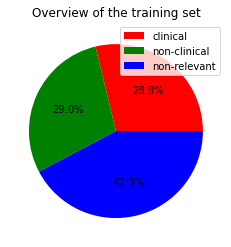

In [4]:
# to represent the distribution of the training set in a circular diagram

labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(training_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the training set')
plt.show()

Counter({'non-relevant': 641, 'non-clinical': 361, 'clinical': 248})
OrderedDict([('clinical', 248), ('non-clinical', 361), ('non-relevant', 641)])
[248, 361, 641]


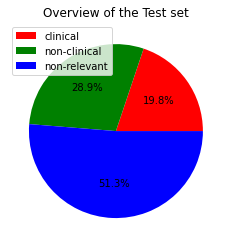

In [5]:
# to represent the distribution of the test:


labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(test_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [6]:
#load text of files 
X_train_text = [Path(file).read_text() for file in training_set]
X_test_text = [Path(file).read_text() for file in test_set]

In [7]:
df_train['text'] = X_train_text
df_test['text'] = X_test_text
df_train=df_train[["label", "text"]]
df_test=df_test[["label", "text"]]
df_train

,label,text
0,clinical,Recovery from anesthesia after craniotomy for ...
1,non-relevant,Retinoids and proliferative verrucous leukopla...
2,clinical,Monitoring flow in extracranial-intracranial b...
3,non-relevant,Urban fitness centers: removing barriers to pr...
4,clinical,"Safety, tolerability, and efficacy of vortioxe..."
...,...,...
2910,clinical,"Incidence, indications, and predictors of adve..."
2911,clinical,Eyelid margin basal cell carcinoma managed wit...
2912,non-relevant,Carbohydrate restriction (with or without addi...
2913,non-clinical,Functional tissue-engineered microtissue deriv...


In [9]:
#dataset_train = Dataset.from_pandas(df_train)
#dataset_test = Dataset.from_pandas(df_test)

debbie_class_names = ["clinical", "non-clinical","non-relevant"]
debbie_features = Features({'text': Value('string'), 'label': ClassLabel(names=debbie_class_names)})
dataset_train = Dataset.from_pandas(df_train, features=debbie_features)
dataset_test = Dataset.from_pandas(df_test, features=debbie_features)
dataset_train

Dataset({
    features: ['text', 'label'],
    num_rows: 2915
})

In [10]:
raw_dataset = DatasetDict({"train":dataset_train,"validation":dataset_test})
raw_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1250
    })
})

In [11]:
raw_train_dataset = raw_dataset["train"]
raw_train_dataset[0]

{'text': 'Recovery from anesthesia after craniotomy for supratentorial tumors: comparison of propofol-remifentanil and sevoflurane-sufentanil (the PROMIFLUNIL trial).\nRapid recovery after supratentorial tumors (STT) removal is important. Short-acting anesthetics, such as propofol and remifentanil might favor this objective. The aim of this study was to compare the recovery of 2 Bispectral index (BIS)-guided anesthesia protocols combining sevoflurane-sufentanil (SS) or propofol-remifentanil (PR) administered during craniotomy for STT. After IRB approval and written consent, patients scheduled for surgical removal of STT were randomized to receive PR or SS. Anesthesia was adjusted to maintain BIS values between 45 and 55. The primary outcome was the time from discontinuation of anesthetics to extubation. Secondary endpoints were: time to respond to a simple order, and to achieve spontaneous ventilation, agitation score at emergence, postoperative Mini Mental State, postoperative Aldrete

In [12]:
raw_train_dataset.features

{'text': Value(dtype='string', id=None),
 'label': ClassLabel(num_classes=3, names=['clinical', 'non-clinical', 'non-relevant'], id=None)}

In [17]:

# Same as before
#checkpoint = "bert-base-uncased"
checkpoint = "dmis-lab/biobert-v1.1"

#model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

#esta parte de aqui no termina utilizandose solamnete el tokenizer


In [18]:
#revisar esta parte
from transformers import AutoConfig, AutoModelForSequenceClassification
# define the mappings as dictionaries
label2id = {'clinical':0, 'non-clinical':1, 'non-relevant': 2}
id2label = {0:'clinical', 1:'non-clinical', 2:'non-relevant'}
# define config
config = AutoConfig.from_pretrained(checkpoint, label2id=label2id, id2label=id2label)
# load model with config
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, config=config)
# export model
#model.save_pretrained(target_name_or_path)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dmis-lab/biobert-v1.1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [19]:
def tokenize_function(example):
    return tokenizer(example["text"], truncation=True) #cuidado agregue padding para usar la segunda opcion

In [20]:
tokenized_datasets = raw_dataset.map(tokenize_function, batched=True)
tokenized_datasets

  0%|          | 0/3 [00:00<?, ?ba/s]

  0%|          | 0/2 [00:00<?, ?ba/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1250
    })
})

In [21]:
tokenized_datasets['train'][0]

{'text': 'Recovery from anesthesia after craniotomy for supratentorial tumors: comparison of propofol-remifentanil and sevoflurane-sufentanil (the PROMIFLUNIL trial).\nRapid recovery after supratentorial tumors (STT) removal is important. Short-acting anesthetics, such as propofol and remifentanil might favor this objective. The aim of this study was to compare the recovery of 2 Bispectral index (BIS)-guided anesthesia protocols combining sevoflurane-sufentanil (SS) or propofol-remifentanil (PR) administered during craniotomy for STT. After IRB approval and written consent, patients scheduled for surgical removal of STT were randomized to receive PR or SS. Anesthesia was adjusted to maintain BIS values between 45 and 55. The primary outcome was the time from discontinuation of anesthetics to extubation. Secondary endpoints were: time to respond to a simple order, and to achieve spontaneous ventilation, agitation score at emergence, postoperative Mini Mental State, postoperative Aldrete

In [22]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [23]:
def compute_metrics(eval_pred):
    metric1 = evaluate.load("precision")
    metric2 = evaluate.load("recall")
    metric3 = evaluate.load("accuracy")
    metric4 = evaluate.load("f1")
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision = metric1.compute(predictions=predictions, references=labels)["precision"]
    recall = metric2.compute(predictions=predictions, references=labels)["recall"]
    accuracy = metric3.compute(predictions=predictions, references=labels)["accuracy"]
    f1 = metric4.compute(predictions=predictions, references=labels)["f1"]
    return {"precision": precision, "recall": recall, "accuracy": accuracy, "f1": f1 }

In [24]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch")
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

/home/jcorvi/.local/lib/python3.6/site-packages/torch/cuda/__init__.py:80: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 9010). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at  ../c10/cuda/CUDAFunctions.cpp:112.)
  return torch._C._cuda_getDeviceCount() > 0


In [ ]:
trainer.train()

The following columns in the training set  don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/home/jcorvi/.local/lib/python3.6/site-packages/transformers/optimization.py:309: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  FutureWarning,
***** Running training *****
  Num examples = 2915
  Num Epochs = 3
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 8
  Gradient Accumulation steps = 1
  Total optimization steps = 1095


Epoch,Training Loss,Validation Loss


In [34]:
#Save the model to path
trainer.save_model("debbie-classifier-model-transformers-1.0.0")

Saving model checkpoint to pretox-sentence-classifier-model-transformers-1.0.0
Configuration saved in pretox-sentence-classifier-model-transformers-1.0.0/config.json
Model weights saved in pretox-sentence-classifier-model-transformers-1.0.0/pytorch_model.bin
tokenizer config file saved in pretox-sentence-classifier-model-transformers-1.0.0/tokenizer_config.json
Special tokens file saved in pretox-sentence-classifier-model-transformers-1.0.0/special_tokens_map.json
